# Tema 3, Exercițiul 3
## Joc între doi jucători

Reguli:
- se aruncă o monedă normală pentru a decide cine începe: $J_0$ sau $J_1$;
- în prima rundă, jucătorul desemnat aruncă cu propriul zar; fie $n$ numărul obținut ($1 \dots 6$);
- în a doua rundă, celălalt jucător aruncă moneda proprie de $2n$ ori; fie $m$ numărul de steme obținute.

Jucătorul din prima rundă câștigă dacă $n \geq m$, altfel câștigă jucătorul din a doua rundă.

Moneda lui $J_1$ este măsluită: $P(\text{stemă}) = 4/7$. Moneda lui $J_0$ este normală ($1/2$), iar zarurile sunt normale.

## a) Simulare: cine are șanse mai mari de câștig?

In [1]:
import numpy as np
rng = np.random.default_rng(0)
N = 10000

wins = {0: 0, 1: 0}
for _ in range(N):
    starter = rng.integers(0, 2)   # cine incepe (runda 1)
    other = 1 - starter            # jucatorul din runda 2
    n = rng.integers(1, 7)         # zarul jucatorului din runda 1
    p = 4/7 if other == 1 else 0.5 # moneda jucatorului din runda 2
    m = rng.binomial(2 * n, p)     # numarul de steme din 2n aruncari
    castigator = starter if n >= m else other
    wins[castigator] += 1

print(f"J0 castiga: {wins[0]/N:.4f}")
print(f"J1 castiga: {wins[1]/N:.4f}")

J0 castiga: 0.4282
J1 castiga: 0.5718


Simularea arată că $J_1$ câștigă mai des (≈ $0.57$). Moneda măsluită îl avantajează: când $J_1$ joacă runda a doua, obține mai multe steme, deci îi este mai ușor să depășească $n$.

## b) Rețea Bayesiană în pgmpy

Variabile:
- $S$, cine începe ($0 = J_0$, $1 = J_1$), uniform $1/2$ (monedă normală);
- $N$, zarul din prima rundă ($1 \dots 6$), uniform;
- $M$, numărul de steme din a doua rundă ($0 \dots 12$).

$M$ depinde de $N$ (se aruncă de $2n$ ori) și de $S$ (cine aruncă în runda 2 este $1-S$, deci moneda folosită). Distribuția lui $M$ este binomială:

$$M \mid S, N \sim \text{Binom}\!\left(2N,\; p\right), \quad p = \begin{cases} 4/7 & \text{dacă în runda 2 joacă } J_1 \\ 1/2 & \text{dacă în runda 2 joacă } J_0 \end{cases}$$

$$S \rightarrow M, \qquad N \rightarrow M$$

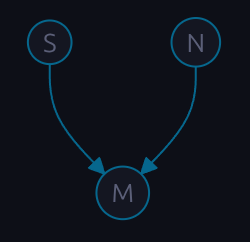

Construim întâi tabelul $P(M \mid S, N)$, coloană cu coloană.

In [ ]:
from scipy.stats import binom
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

Mmax = 12  # 2 * 6

# Fiecare coloana e distributia completa a lui M (steme = 0..12) pentru o pereche
# fixata (S, N)
# (S=0,N=1), ..., (S=0,N=6), (S=1,N=1), ..., (S=1,N=6)
coloane = []
for s in (0, 1):
    for n in range(1, 7):
        p = 4/7 if (1 - s) == 1 else 0.5   # moneda jucatorului din runda 2 (1 - s)
        # P(M = k | S = s, N = n) pentru k = 0..12
        coloane.append([binom.pmf(k, 2 * n, p) for k in range(Mmax + 1)])
# transpunem coloanele ca randurile sa fie valorile lui M,
# iar coloanele perechile (S, N), asa cum cere TabularCPD.
cpd_M_vals = np.array(coloane).T   # forma (13 valori M, 12 perechi S,N)

/home/stefan/Laboratoare/PMP/PMP-2026/.venv/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [3]:
import pandas as pd
coloane_etichete = [f"S={s},N={n}" for s in (0, 1) for n in range(1, 7)]
tabel_M = pd.DataFrame(cpd_M_vals, columns=coloane_etichete)
tabel_M.index.name = "M"
print(tabel_M.round(3))

    S=0,N=1  S=0,N=2  S=0,N=3  S=0,N=4  S=0,N=5  S=0,N=6  S=1,N=1  S=1,N=2  \
M                                                                            
0     0.184    0.034    0.006    0.001    0.000    0.000     0.25    0.063   
1     0.490    0.180    0.050    0.012    0.003    0.001     0.50    0.250   
2     0.327    0.360    0.165    0.057    0.017    0.005     0.25    0.375   
3     0.000    0.320    0.294    0.151    0.059    0.020     0.00    0.250   
4     0.000    0.107    0.294    0.252    0.139    0.060     0.00    0.062   
5     0.000    0.000    0.157    0.269    0.222    0.128     0.00    0.000   
6     0.000    0.000    0.035    0.179    0.247    0.199     0.00    0.000   
7     0.000    0.000    0.000    0.068    0.188    0.228     0.00    0.000   
8     0.000    0.000    0.000    0.011    0.094    0.190     0.00    0.000   
9     0.000    0.000    0.000    0.000    0.028    0.112     0.00    0.000   
10    0.000    0.000    0.000    0.000    0.004    0.045     0.0

Definim CPD-urile și construim modelul.

In [4]:
model = DiscreteBayesianNetwork([("S", "M"), ("N", "M")])
# S fara parinti: moneda normala
cpd_S = TabularCPD("S", 2,
    [[0.5],   # P(S=0) -> incepe J0
     [0.5]])  # P(S=1) -> incepe J1
# N fara parinti: zar normal, cate o coloana cu probabilitatea fiecarei fete
cpd_N = TabularCPD("N", 6, [[1/6]] * 6)   # P(N=1) .. P(N=6), fiecare 1/6
cpd_M = TabularCPD("M", Mmax + 1, cpd_M_vals.tolist(),
                   evidence=["S", "N"], evidence_card=[2, 6])

model.add_cpds(cpd_S, cpd_N, cpd_M)
print("model valid:", model.check_model())

model valid: True


## c) Cine e cel mai probabil să fi început, dacă în runda 2 s-a obținut o singură stemă ($M=1$)?

In [5]:
inf = VariableElimination(model)
q = inf.query(["S"], evidence={"M": 1}, show_progress=False)
print(q)

+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.4529 |
+------+----------+
| S(1) |   0.5471 |
+------+----------+


Rezultat: $P(S=0 \mid M=1) \approx 0.453$ și $P(S=1 \mid M=1) \approx 0.547$.

Deci este mai probabil ca $J_1$ să fi început.